# Waveform models

`generate_windowed_waveform` generates a signal on a uniform grid and
optionally tapers it. That is all it does - it **does not pad**, because
padding belongs to the grid a record will be analysed on rather than to the
waveform, and the two response paths need different amounts of it. See
`padding_explained.ipynb`.

Models are dispatched by name through a registry, with their parameters passed
as `model_kwargs`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import jax.numpy as jnp

import WDM
from WDM_LISAresponse.code.waveforms import waveforms
from WDM_LISAresponse.code.utils import utils

print("waveform models:", tuple(waveforms._get_waveform_models()))
print("window functions:", tuple(waveforms._get_window_functions()))

dt, Nf, q = 5.0, 32, 8
N = 4096

def plot_pair(times, h_plus, h_cross, title, wdm=None):
    """Time series, and its wavelet coefficients when a transform is given."""
    ncols = 2 if wdm is not None else 1
    fig, axes = plt.subplots(1, ncols, figsize=(6.2 * ncols, 3.4), squeeze=False)
    t0 = times[0]
    axes[0, 0].plot((times - t0) / 3600, h_plus, lw=.7, label="$h_+$")
    axes[0, 0].plot((times - t0) / 3600, h_cross, lw=.7, alpha=.7, label="$h_\\times$")
    axes[0, 0].set(xlabel="time since $t_0$ [hours]", ylabel="strain", title=title)
    axes[0, 0].legend(loc="upper right"); axes[0, 0].grid(alpha=.3)
    if wdm is not None:
        coeffs = np.abs(np.asarray(wdm.dwt(jnp.asarray(h_plus))))
        axes[0, 1].imshow(coeffs.T, aspect="auto", origin="lower", cmap="magma",
                          extent=[0, (times[-1]-t0)/3600, 0, wdm.Nf * wdm.dF * 1e3])
        axes[0, 1].set(xlabel="time since $t_0$ [hours]", ylabel="frequency [mHz]",
                       title=f"$|w_{{nm}}|$  ({wdm.Nt} x {wdm.Nf})")
    fig.tight_layout()
    return fig

wdm = WDM.WDM.WDM_transform(dt=dt, Nf=Nf, N=N, q=q)
print(f"\nWDM grid: Nt = {wdm.Nt}, Nf = {wdm.Nf}, "
      f"dT = {wdm.dT:.0f} s, dF = {wdm.dF*1e3:.3f} mHz")

waveform models: ('monochromatic', 'linear_freq', 'emri')
window functions: ('tukey',)



WDM grid: Nt = 128, Nf = 32, dT = 160 s, dF = 3.125 mHz


## `monochromatic`

A fixed-frequency sinusoid.

| parameter | meaning |
|---|---|
| `A_plus`, `A_cross` | polarisation amplitudes [strain] |
| `f` | GW frequency [Hz] |
| `phi_0` | initial phase [rad] |

The convention is $h_+ = A_+ \cos\phi$, $h_\times = A_\times \sin\phi$, set in
one place by `waveform_polarisations`.

In the wavelet plane it should be a single horizontal stripe: constant
frequency, all time.

h_plus  = A_plus  * cos(2 pi f t + phi_0),  peak 1.00e-21
h_cross = A_cross * sin(2 pi f t + phi_0),  peak 6.00e-22
band containing 5 mHz: m = 2


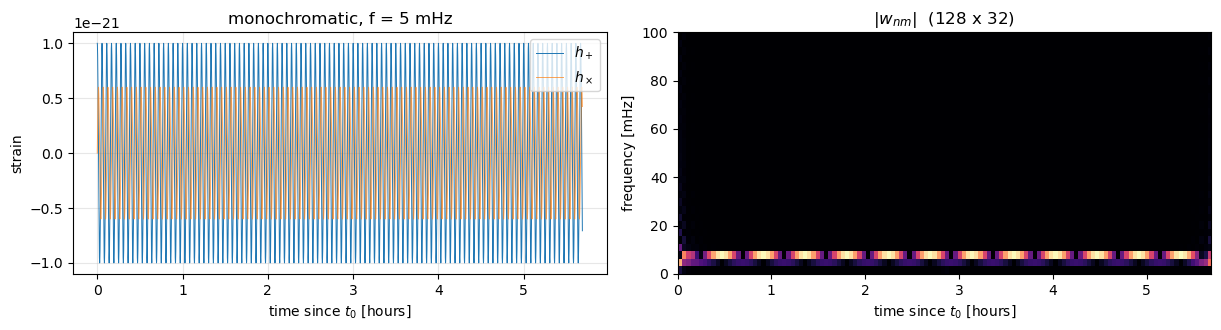

In [2]:
times, h_plus, h_cross = waveforms.generate_windowed_waveform(
    "monochromatic", t0=1.0e7, dt=dt, N=N,
    model_kwargs=dict(A_plus=1.0e-21, A_cross=0.6e-21, f=5.0e-3, phi_0=0.0))

plot_pair(times, h_plus, h_cross, "monochromatic, f = 5 mHz", wdm)
print(f"h_plus  = A_plus  * cos(2 pi f t + phi_0),  peak {np.abs(h_plus).max():.2e}")
print(f"h_cross = A_cross * sin(2 pi f t + phi_0),  peak {np.abs(h_cross).max():.2e}")
print(f"band containing 5 mHz: m = {int(round(5.0e-3 / wdm.dF))}")

## `linear_freq`

A linear-in-time frequency sweep - the simplest thing with structure in both
time and frequency, which makes it the useful one for exercising the response.

| parameter | meaning |
|---|---|
| `A_plus`, `A_cross` | polarisation amplitudes [strain] |
| `f_start`, `f_end` | frequency at the first and last sample [Hz] |
| `phi_0` | initial phase [rad] |

The phase is $\phi = \phi_0 + 2\pi(f_{\rm start}\tau + \tfrac{1}{2}k\tau^2)$
with $\tau = t - t_0$ and the chirp rate $k$ fixed so the frequency reaches
`f_end` at the **last sample**. It is a diagonal line in the wavelet plane.

chirp rate k = (f_end - f_start)/(t[-1] - t[0]) = 8.791e-07 Hz/s
the sweep reaches f_end at the LAST SAMPLE, not at any nominal T_obs


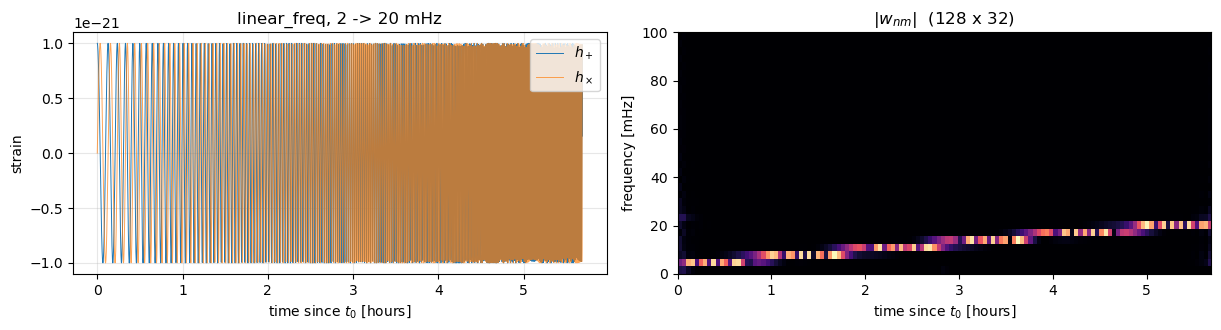

In [3]:
times, h_plus, h_cross = waveforms.generate_windowed_waveform(
    "linear_freq", t0=1.0e7, dt=dt, N=N,
    model_kwargs=dict(A_plus=1.0e-21, A_cross=1.0e-21,
                      f_start=2.0e-3, f_end=2.0e-2, phi_0=0.0))

plot_pair(times, h_plus, h_cross, "linear_freq, 2 -> 20 mHz", wdm)

span = times[-1] - times[0]
print(f"chirp rate k = (f_end - f_start)/(t[-1] - t[0]) = "
      f"{(2.0e-2 - 2.0e-3)/span:.3e} Hz/s")
print("the sweep reaches f_end at the LAST SAMPLE, not at any nominal T_obs")

## Windowing

Windows are a separate registry, applied after generation. Only `tukey` is
registered.

`alpha` is the fraction of the record covered by the taper: `alpha=0` leaves
the signal untouched, `alpha=1` is a Hann window.

the window tapers only - it adds no padding


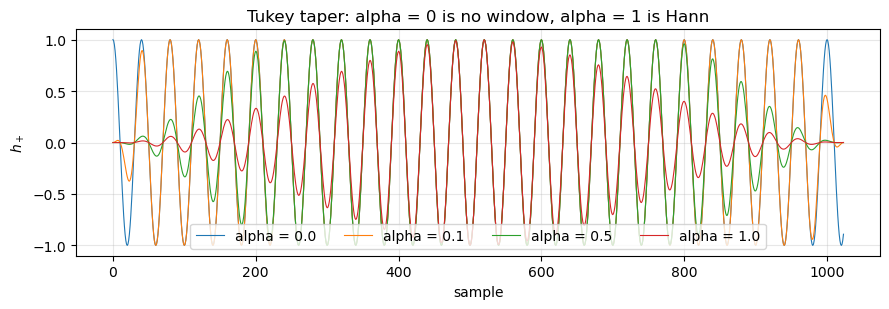

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.2))
for alpha in [0.0, 0.1, 0.5, 1.0]:
    _, hp, _ = waveforms.generate_windowed_waveform(
        "monochromatic", t0=0.0, dt=dt, N=1024,
        model_kwargs=dict(A_plus=1.0, A_cross=0.0, f=5.0e-3, phi_0=0.0),
        window_function="tukey", window_kwargs=dict(alpha=alpha))
    ax.plot(hp, lw=.8, label=f"alpha = {alpha}")
ax.set(xlabel="sample", ylabel="$h_+$", title="Tukey taper: alpha = 0 is no window, alpha = 1 is Hann")
ax.legend(loc="lower center", ncol=4); ax.grid(alpha=.3)
fig.tight_layout()
print("the window tapers only - it adds no padding")

## Setting the duration

Give either `N` (samples) or `T_obs` (**years**, converted with the sidereal
year), never both.

In [5]:
t_by_N, _, _ = waveforms.generate_windowed_waveform(
    "monochromatic", t0=0.0, dt=dt, N=8192,
    model_kwargs=dict(A_plus=1.0, A_cross=0.0, f=5e-3, phi_0=0.0))

t_by_T, _, _ = waveforms.generate_windowed_waveform(
    "monochromatic", t0=0.0, dt=dt, T_obs=0.01,
    model_kwargs=dict(A_plus=1.0, A_cross=0.0, f=5e-3, phi_0=0.0))

print(f"N = 8192       -> {len(t_by_N)} samples")
print(f"T_obs = 0.01 y -> {len(t_by_T)} samples "
      f"(= floor(0.01 * {waveforms.YRSID_SI:.6g} / {dt}))")

for kwargs, why in [(dict(), "neither given"),
                    (dict(N=64, T_obs=1.0), "both given"),
                    (dict(N=1), "N < 2"),
                    (dict(N=64, waveform_model="nope"), "unknown model")]:
    call = dict(waveform_model="monochromatic", t0=0.0, dt=dt,
                model_kwargs=dict(A_plus=1.0, A_cross=0.0, f=5e-3, phi_0=0.0))
    call.update(kwargs)
    try:
        waveforms.generate_windowed_waveform(**call)
        print(f"  {why:16s} -> no error")
    except ValueError as exc:
        print(f"  {why:16s} -> ValueError: {exc}")

N = 8192       -> 8192 samples
T_obs = 0.01 y -> 63116 samples (= floor(0.01 * 3.15581e+07 / 5.0))
  neither given    -> ValueError: Either T_obs or N must be provided.
  both given       -> ValueError: Provide only one of T_obs or N, not both.
  N < 2            -> ValueError: At least two samples are required, so N must be >= 2.
  unknown model    -> ValueError: Waveform model 'nope' is not available.


## `emri`

Needs [FEW](https://bhptoolkit.org/FastEMRIWaveforms/), which is an optional
dependency - the generator object is passed in as `td_gen` rather than built
here, so the package never imports FEW itself.

| parameter | meaning |
|---|---|
| `td_gen` | a FEW generator, e.g. `GenerateEMRIWaveform(...)` |
| `m1`, `m2` | central and secondary mass [$M_\odot$] |
| `a`, `p0`, `e0`, `x0` | spin and initial orbital elements |
| `dist` | luminosity distance [Gpc] |
| `qS`/`phiS`, or `theta`/`phi` | sky location [rad] |
| `qK`, `phiK` | spin orientation [rad] |
| `Phi_phi0`, `Phi_theta0`, `Phi_r0` | initial phases [rad] |
| `eps` | mode selection threshold |

**Heads up:** FEW's first call builds a precompute table, and it is slow
and memory hungry - noticeably more so than anything else in this
notebook. Run the cell when you have the machine to spare. It is skipped
cleanly if FEW is not installed.\n\nThis cell is tagged `skip-execution`, so a batch `nbconvert --execute` run\nleaves it alone. Running it yourself in Jupyter works normally.

In [ ]:
# NOTE: the first FEW call builds a precompute table and is slow - expect it to
# take a while and to be memory hungry. Everything above this cell is cheap.
EMRI_PARAMS = dict(m1=1.0e6, m2=10.0, a=0.9, p0=12.0, e0=0.3, x0=1.0,
                   dist=1.0, theta=np.pi/3, phi=0.4, qK=np.pi/3, phiK=np.pi/3,
                   Phi_phi0=np.pi/3, Phi_theta0=0.0, Phi_r0=np.pi/3, eps=1.0e-2)

try:
    from few.waveform import GenerateEMRIWaveform
except ImportError:
    print("FEW is not installed - skipping. Install it to run this cell.")
else:
    print("building the FEW generator (first call is slow)...")
    td_gen = GenerateEMRIWaveform("FastKerrEccentricEquatorialFlux",
                                  sum_kwargs=dict(pad_output=True, odd_len=True),
                                  return_list=True, force_backend="cpu")

    times, h_plus, h_cross = waveforms.generate_windowed_waveform(
        "emri", t0=1.0e7, dt=10.0, N=1 << 16,
        model_kwargs=dict(td_gen=td_gen, **EMRI_PARAMS),
        window_function="tukey", window_kwargs=dict(alpha=0.05))

    wdm_emri = WDM.WDM.WDM_transform(dt=10.0, Nf=64, N=len(times), q=q)
    plot_pair(times, h_plus, h_cross, "EMRI (FEW)", wdm_emri)
    print("FEW output is forced to len(times): truncated if it overshoots,")
    print("zero filled if the inspiral plunges early. Both are expected.")

## Adding a model

Write a generator taking `times` plus its own keyword parameters and returning
`(h_plus, h_cross)`, then add it to `_get_waveform_models`. Nothing else needs
to change - validation, windowing and duration handling are all in
`generate_windowed_waveform`.